# Stage 8b — Group Importance & Ablation

Take the predictor stack from 8a, add it to the model, and let **group-level evidence** decide which families of features pull their weight.

## Why per-feature importance lies when predictors are correlated

Two collinear features (e.g. SSH and SLA both proxying the Atlantic-Ionian Stream) **split** their shared importance — each looks weak individually, and a naive 'drop the weakest' filter throws away both. The fix is three-layered, exactly as PLAN.md prescribes:

1. **Correlation heatmap** — find collinear groups *before* trusting any importance.
2. **Grouped permutation importance** — shuffle a whole *group* of correlated features together; the val-R² drop is the group's joint contribution.
3. **Group ablation** — drop a group, retrain, measure ΔR². A group that vanishes from the model without changing val-R² isn't earning its place — even if individual columns looked important.

## Outputs
- `data/processed/supervised_sample_v2.parquet` — extended sample with the new predictors
- `data/processed/feature_manifest_v2.json` — feature/group definitions
- `data/processed/group_importance.csv` — permutation + ablation deltas per group
- `figs/08_correlation_heatmap.png`, `figs/08_group_importance.png`, `figs/08_group_ablation.png`
- `models/xgb_v2_h{1..7}.json` — final retrained models on the selected feature set

## 8b.0 — Configuration & load all cubes

Load every cube. **Extract surface from 3D fields immediately** so we never carry 75-level memory loads beyond this cell.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xarray as xr

RAW_DIR  = Path("data/raw")
PROC_DIR = Path("data/processed"); PROC_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = Path("models");        MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR   = Path("figs");          FIG_DIR.mkdir(parents=True, exist_ok=True)

# Cubes from Notebook 1/3/8a
chl_da   = xr.open_dataset(RAW_DIR / "chl_malta_2021_2023.nc").CHL
sst_da   = xr.open_dataset(RAW_DIR / "sst_malta_2021_2023.nc").analysed_sst
bathy_ds = xr.open_dataset(RAW_DIR / "bathy_malta.nc")

phy_sal_da = xr.open_dataset(RAW_DIR / "phy_sal.nc").so
phy_cur_ds = xr.open_dataset(RAW_DIR / "phy_cur.nc")
phy_ssh_da = xr.open_dataset(RAW_DIR / "phy_ssh.nc").zos
phy_mld_da = xr.open_dataset(RAW_DIR / "phy_mld.nc").mlotst
kd490_da   = xr.open_dataset(RAW_DIR / "oc_kd490.nc").KD490

era5_path = RAW_DIR / "era5_wind_2021_2023.nc"
have_wind = era5_path.exists()
if have_wind:
    era5 = xr.open_dataset(era5_path)
    print("ERA5 wind: present")
else:
    era5 = None
    print("ERA5 wind: missing — wind group will be skipped")

# Surface extraction — drops the depth dim on the 3D cubes
def surface(da):
    for cand in ("depth", "lev", "z"):
        if cand in da.dims:
            return da.isel({cand: 0}).drop_vars(cand, errors="ignore")
    return da

phy_sal_da = surface(phy_sal_da)
phy_cur_uo = surface(phy_cur_ds.uo)
phy_cur_vo = surface(phy_cur_ds.vo)
phy_ssh_da = surface(phy_ssh_da)
phy_mld_da = surface(phy_mld_da)

# Standardise lat/lon names — ERA5 uses lat/lon, CMEMS uses latitude/longitude
def std_coords(da):
    rn = {}
    if "lat" in da.coords and "latitude" not in da.coords:  rn["lat"] = "latitude"
    if "lon" in da.coords and "longitude" not in da.coords: rn["lon"] = "longitude"
    return da.rename(rn) if rn else da

for name in ("phy_sal_da","phy_cur_uo","phy_cur_vo","phy_ssh_da","phy_mld_da","kd490_da"):
    globals()[name] = std_coords(globals()[name])

print("\nSurface shapes:")
for name in ["phy_sal_da","phy_cur_uo","phy_cur_vo","phy_ssh_da","phy_mld_da","kd490_da"]:
    print(f"  {name:14s} {dict(globals()[name].sizes)}")

ERA5 wind: present

Surface shapes:
  phy_sal_da     {'time': 1095, 'latitude': 48, 'longitude': 85}
  phy_cur_uo     {'time': 1095, 'latitude': 48, 'longitude': 85}
  phy_cur_vo     {'time': 1095, 'latitude': 48, 'longitude': 85}
  phy_ssh_da     {'time': 1095, 'latitude': 48, 'longitude': 85}
  phy_mld_da     {'time': 1095, 'latitude': 48, 'longitude': 85}
  kd490_da       {'time': 1095, 'latitude': 198, 'longitude': 272}


## 8b.1 — Derived wind features

Raw `u10`/`v10` aren't very informative on their own. The physics that drives ocean colour is in three derivatives:

- **Wind speed** `√(u² + v²)` — mixing energy.
- **Wind-stress curl** — Ekman pumping → upwelling/downwelling proxy. Computed with finite differences on the grid.
- **Bakun-style upwelling index** — alongshore wind stress integrated over a window (3- and 7-day). For now we use **wind speed × 3-day rolling** as a lightweight proxy; a true Bakun index needs a coastline orientation, which we'll add only if 8c/ablation shows wind matters at all.

If ERA5 is missing, this whole cell becomes a no-op and the wind group is dropped from the rest of the analysis.

In [2]:
wind_features = {}
if have_wind:
    # ERA5 may name them u10/v10 or expver/u10. Be defensive.
    u = era5["u10"] if "u10" in era5 else era5["10m_u_component_of_wind"]
    v = era5["v10"] if "v10" in era5 else era5["10m_v_component_of_wind"]

    # Drop singleton expver/number dims (ERA5T artefact) and rename ERA5's new
    # 'valid_time' dim back to 'time' so it matches every other cube.
    def _normalise_era5(da):
        for dim in ("expver", "number"):
            if dim in da.dims:
                da = da.isel({dim: 0}).drop_vars(dim, errors="ignore")
        if "valid_time" in da.dims and "time" not in da.dims:
            da = da.rename({"valid_time": "time"})
        if "valid_time" in da.coords:
            da = da.drop_vars("valid_time", errors="ignore")
        return da

    u = _normalise_era5(u)
    v = _normalise_era5(v)
    u = std_coords(u); v = std_coords(v)

    # ERA5 latitude is typically descending — make ascending to match CHL
    if u.latitude.values[0] > u.latitude.values[-1]:
        u = u.sortby("latitude"); v = v.sortby("latitude")

    speed = np.sqrt(u**2 + v**2).rename("wind_speed")
    speed_roll3 = speed.rolling(time=3, min_periods=1).mean().rename("wind_speed_roll3")
    speed_roll7 = speed.rolling(time=7, min_periods=1).mean().rename("wind_speed_roll7")

    # Wind-stress curl ≈ ∂τy/∂x − ∂τx/∂y where τ ≈ rho_air * Cd * |U| * U
    # Use simplified proxy: curl of (speed*u, speed*v) on the grid (cheap, dimensional only).
    rho_cd = 0.0015 * 1.225        # bulk drag × air density (kg m⁻¹)
    tau_x = (rho_cd * speed * u)
    tau_y = (rho_cd * speed * v)
    # finite-difference derivatives along lon/lat axes (in degrees, not metres — proxy only)
    curl = tau_y.differentiate("longitude") - tau_x.differentiate("latitude")
    curl = curl.rename("wind_stress_curl")

    wind_features = dict(
        wind_speed       = speed,
        wind_speed_roll3 = speed_roll3,
        wind_speed_roll7 = speed_roll7,
        wind_stress_curl = curl,
        wind_u           = u,
        wind_v           = v,
    )
    print("Wind features built:")
    for k, v in wind_features.items():
        print(f"  {k:18s} {dict(v.sizes)}")
else:
    print("ERA5 missing — no wind features")

Wind features built:
  wind_speed         {'time': 1095, 'latitude': 9, 'longitude': 15}
  wind_speed_roll3   {'time': 1095, 'latitude': 9, 'longitude': 15}
  wind_speed_roll7   {'time': 1095, 'latitude': 9, 'longitude': 15}
  wind_stress_curl   {'time': 1095, 'latitude': 9, 'longitude': 15}
  wind_u             {'time': 1095, 'latitude': 9, 'longitude': 15}
  wind_v             {'time': 1095, 'latitude': 9, 'longitude': 15}


## 8b.2 — Regrid every predictor onto the CHL grid + time alignment

**Rule (PLAN.md):** the CHL grid is finest, so everything gets interpolated *onto* it. Spatial interpolation of ERA5 from ~31 km to 1 km doesn't invent real fine structure — it just makes the arrays addressable on a common grid. For a tree model, what matters is that values at the same `(time, lat, lon)` line up.

For time alignment, we use `reindex(time=chl.time, method='nearest', tolerance=1 day)` — same convention as Notebook 4.

In [3]:
target_lat = chl_da.latitude
target_lon = chl_da.longitude
target_time = chl_da.time

def to_chl_grid(da, has_time=True):
    da = da.interp(latitude=target_lat, longitude=target_lon)
    if has_time and "time" in da.dims:
        da = da.reindex(time=target_time, method="nearest", tolerance=np.timedelta64(1, "D"))
    return da

predictors = {
    "salinity"     : to_chl_grid(phy_sal_da),
    "current_u"    : to_chl_grid(phy_cur_uo),
    "current_v"    : to_chl_grid(phy_cur_vo),
    "ssh"          : to_chl_grid(phy_ssh_da),
    "mld"          : to_chl_grid(phy_mld_da),
    "kd490"        : to_chl_grid(kd490_da),
}

# current speed (handy summary)
predictors["current_speed"] = np.sqrt(predictors["current_u"]**2 + predictors["current_v"]**2)

# bathymetry (static)
elev_var = next(v for v in bathy_ds.data_vars if v in ("z","elevation","bed_elevation"))
depth_static = (-bathy_ds[elev_var].where(bathy_ds[elev_var] < 0, 0))
depth_static = std_coords(depth_static).interp(latitude=target_lat, longitude=target_lon)
predictors["depth_m"] = depth_static

# wind (regrid + reindex onto chl time)
for k, da in wind_features.items():
    predictors[k] = to_chl_grid(da)

print(f"Regridded predictors: {len(predictors)}")
for k, v in predictors.items():
    print(f"  {k:18s} {dict(v.sizes)}")

Regridded predictors: 14
  salinity           {'time': 1095, 'latitude': 198, 'longitude': 272}
  current_u          {'time': 1095, 'latitude': 198, 'longitude': 272}
  current_v          {'time': 1095, 'latitude': 198, 'longitude': 272}
  ssh                {'time': 1095, 'latitude': 198, 'longitude': 272}
  mld                {'time': 1095, 'latitude': 198, 'longitude': 272}
  kd490              {'time': 1095, 'latitude': 198, 'longitude': 272}
  current_speed      {'time': 1095, 'latitude': 198, 'longitude': 272}
  depth_m            {'latitude': 198, 'longitude': 272}
  wind_speed         {'time': 1095, 'latitude': 198, 'longitude': 272}
  wind_speed_roll3   {'time': 1095, 'latitude': 198, 'longitude': 272}
  wind_speed_roll7   {'time': 1095, 'latitude': 198, 'longitude': 272}
  wind_stress_curl   {'time': 1095, 'latitude': 198, 'longitude': 272}
  wind_u             {'time': 1095, 'latitude': 198, 'longitude': 272}
  wind_v             {'time': 1095, 'latitude': 198, 'longitude': 

## 8b.3 — Build the extended feature dataset

Same skeleton as Notebook 4 (target = `log10(CHL)` daily; lags of `log_chl_t0`; SST/DOY features) **plus** the new predictor families. Then sample stratified-by-month (same SEED as N4 → reproducible).

We drop `gap_age` this time — Notebook 4 showed it's a dud in this sampling design.

In [4]:
# Convert SST K → °C if needed
sst = sst_da
if float(sst.isel(time=0).max()) > 200:
    sst = sst - 273.15
sst_on_chl = sst.interp(latitude=target_lat, longitude=target_lon)
sst_on_chl = sst_on_chl.reindex(time=target_time, method="nearest", tolerance=np.timedelta64(1,"D"))

log_chl = np.log10(chl_da).rename("log_chl")
target_series = log_chl   # DAILY per Gate 2 decision

feat = xr.Dataset()

# --- group: chl_history ---
feat["log_chl_t0"]         = target_series
for lag in [1, 2, 3, 7, 14]:
    feat[f"log_chl_lag{lag}"] = target_series.shift(time=lag)
feat["log_chl_roll7_mean"] = target_series.rolling(time=7, min_periods=1).mean()
feat["log_chl_roll7_std"]  = target_series.rolling(time=7, min_periods=2).std()

# --- group: sst ---
feat["sst_t0"]         = sst_on_chl
feat["sst_lag1"]       = sst_on_chl.shift(time=1)
feat["sst_roll7_mean"] = sst_on_chl.rolling(time=7, min_periods=1).mean()

# --- group: static_time ---
feat["depth_m"] = predictors["depth_m"].broadcast_like(target_series)
doy = target_series.time.dt.dayofyear
feat["doy_sin"] = np.sin(2*np.pi*doy/365.25).broadcast_like(target_series)
feat["doy_cos"] = np.cos(2*np.pi*doy/365.25).broadcast_like(target_series)

# --- group: salinity ---
feat["salinity"]      = predictors["salinity"]
feat["salinity_roll7"] = predictors["salinity"].rolling(time=7, min_periods=1).mean()

# --- group: currents_ssh ---
feat["current_u"]     = predictors["current_u"]
feat["current_v"]     = predictors["current_v"]
feat["current_speed"] = predictors["current_speed"]
feat["ssh"]           = predictors["ssh"]

# --- group: mld ---
feat["mld"]       = predictors["mld"]
feat["mld_lag1"]  = predictors["mld"].shift(time=1)
feat["mld_roll7"] = predictors["mld"].rolling(time=7, min_periods=1).mean()

# --- group: optics ---
feat["kd490"]       = predictors["kd490"]
feat["kd490_roll7"] = predictors["kd490"].rolling(time=7, min_periods=1).mean()

# --- group: wind (only if ERA5 present) ---
if have_wind:
    feat["wind_speed"]       = predictors["wind_speed"]
    feat["wind_speed_roll3"] = predictors["wind_speed_roll3"]
    feat["wind_speed_roll7"] = predictors["wind_speed_roll7"]
    feat["wind_stress_curl"] = predictors["wind_stress_curl"]
    feat["wind_u"]           = predictors["wind_u"]
    feat["wind_v"]           = predictors["wind_v"]

# --- targets ---
HORIZONS = [1, 2, 3, 4, 5, 6, 7]
targets = xr.Dataset({f"target_h{h}": target_series.shift(time=-h) for h in HORIZONS})

print(f"Total feature columns: {len(feat.data_vars)}")

c:\GIT\mcast.pages.ai.v2\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Total feature columns: 31


## 8b.4 — Flatten & stratified-by-month sample

Same procedure as Notebook 4. Same SEED so sample composition is deterministic.

In [5]:
import gc

SAMPLE_PER_MONTH = 10_000
SEED             = 42

# Cast to float32 — halves memory, no precision loss that matters at our scale.
for v in feat.data_vars:
    if feat[v].dtype == np.float64:
        feat[v] = feat[v].astype(np.float32)
for v in targets.data_vars:
    if targets[v].dtype == np.float64:
        targets[v] = targets[v].astype(np.float32)

# Stratify by (year, month) and process one bucket at a time.
# Each bucket is ~30 days × 87k pixels = ~2.6M rows → manageable.
times = pd.DatetimeIndex(feat.time.values)
years = sorted(set(times.year))
n_per_bucket = max(1, SAMPLE_PER_MONTH // len(years))   # so each calendar month still ends up near SAMPLE_PER_MONTH

print(f"Years           : {years}")
print(f"Buckets         : {len(years)} × 12 = {len(years)*12}")
print(f"Rows per bucket : {n_per_bucket:,} (total target ≈ {n_per_bucket * len(years) * 12:,})")

sample_parts = []
for year in years:
    for cal_month in range(1, 13):
        mask = (times.year == year) & (times.month == cal_month)
        if not mask.any():
            continue
        idx = np.where(mask)[0]

        feat_chunk = feat.isel(time=idx)
        tgt_chunk  = targets.isel(time=idx)
        df_chunk   = pd.concat([feat_chunk.to_dataframe(),
                                tgt_chunk.to_dataframe()],
                               axis=1).reset_index()
        valid = df_chunk.dropna(subset=["log_chl_t0"])
        if len(valid) > n_per_bucket:
            valid = valid.sample(n_per_bucket, random_state=SEED)
        sample_parts.append(valid)
        del feat_chunk, tgt_chunk, df_chunk
        gc.collect()
    print(f"  {year} done — running sample size: {sum(len(p) for p in sample_parts):,}")

sample = pd.concat(sample_parts, ignore_index=True)
sample["month"] = sample["time"].dt.month

sample.to_parquet(PROC_DIR / "supervised_sample_v2.parquet")
print(f"\nSampled shape: {sample.shape}")
print(f"Saved → {PROC_DIR / 'supervised_sample_v2.parquet'}  "
      f"({(PROC_DIR / 'supervised_sample_v2.parquet').stat().st_size/1e6:.1f} MB)")
print(f"\nRows per calendar month:")
print(sample['month'].value_counts().sort_index().to_string())

Years           : [2021, 2022, 2023]
Buckets         : 3 × 12 = 36
Rows per bucket : 3,333 (total target ≈ 119,988)
  2021 done — running sample size: 39,996
  2022 done — running sample size: 79,992
  2023 done — running sample size: 119,988

Sampled shape: (119988, 44)
Saved → data\processed\supervised_sample_v2.parquet  (22.5 MB)

Rows per calendar month:
month
1     9999
2     9999
3     9999
4     9999
5     9999
6     9999
7     9999
8     9999
9     9999
10    9999
11    9999
12    9999


## 8b.5 — Define feature groups

**Groups are the unit of analysis from here on.** Permutation importance and ablation both operate on groups. A group either earns its place or it doesn't — we don't keep half a group.

In [7]:
META_COLS   = ["time", "latitude", "longitude", "month"]
TARGET_COLS = [f"target_h{h}" for h in HORIZONS]

# Defensively drop ERA5 metadata scalars that can slip through as columns:
#   expver = ERA5 stream tag (e.g. '0001' for operational)
#   number = ensemble member (always 0 for deterministic reanalysis)
# Both are constants → zero feature signal; keeping them just bloats the matrix.
ERA5_METADATA = ["expver", "number"]
for col in ERA5_METADATA:
    if col in sample.columns:
        sample = sample.drop(columns=col)

FEATURE_COLS = [c for c in sample.columns if c not in META_COLS + TARGET_COLS]

GROUPS = {
    "chl_history":  [c for c in FEATURE_COLS if c.startswith(("log_chl_lag", "log_chl_roll", "log_chl_t0"))],
    "sst":          [c for c in FEATURE_COLS if c.startswith("sst_")],
    "static_time":  [c for c in FEATURE_COLS if c in ("depth_m", "doy_sin", "doy_cos")],
    "salinity":     [c for c in FEATURE_COLS if c.startswith("salinity")],
    "currents_ssh": [c for c in FEATURE_COLS if c.startswith(("current_", "ssh"))],
    "mld":          [c for c in FEATURE_COLS if c.startswith("mld")],
    "optics":       [c for c in FEATURE_COLS if c.startswith("kd490")],
    "wind":         [c for c in FEATURE_COLS if c.startswith("wind")],
}
GROUPS = {k: v for k, v in GROUPS.items() if v}   # drop empty (e.g. wind without ERA5)

# Sanity: every feature lives in exactly one group
all_grouped = sorted({c for cols in GROUPS.values() for c in cols})
missing = set(FEATURE_COLS) - set(all_grouped)
if missing:
    print(f"WARNING: {len(missing)} ungrouped columns: {missing}")

manifest_v2 = dict(
    meta_cols=META_COLS, target_cols=TARGET_COLS,
    feature_cols=FEATURE_COLS, groups=GROUPS, horizons=HORIZONS,
)
with open(PROC_DIR / "feature_manifest_v2.json", "w") as f:
    json.dump(manifest_v2, f, indent=2)

print(f"Total features  : {len(FEATURE_COLS)}")
for g, cols in GROUPS.items():
    print(f"  {g:14s} {len(cols)}  → {cols}")

Total features  : 31
  chl_history    8  → ['log_chl_t0', 'log_chl_lag1', 'log_chl_lag2', 'log_chl_lag3', 'log_chl_lag7', 'log_chl_lag14', 'log_chl_roll7_mean', 'log_chl_roll7_std']
  sst            3  → ['sst_t0', 'sst_lag1', 'sst_roll7_mean']
  static_time    3  → ['depth_m', 'doy_sin', 'doy_cos']
  salinity       2  → ['salinity', 'salinity_roll7']
  currents_ssh   4  → ['current_u', 'current_v', 'current_speed', 'ssh']
  mld            3  → ['mld', 'mld_lag1', 'mld_roll7']
  optics         2  → ['kd490', 'kd490_roll7']
  wind           6  → ['wind_speed', 'wind_speed_roll3', 'wind_speed_roll7', 'wind_stress_curl', 'wind_u', 'wind_v']


## 8b.6 — Correlation heatmap

Look at pairwise Spearman correlation **before** trusting any per-feature importance number. Pairs with `|ρ| > 0.9` are functionally one variable — they'll split their importance and we read them as a group, not individually.

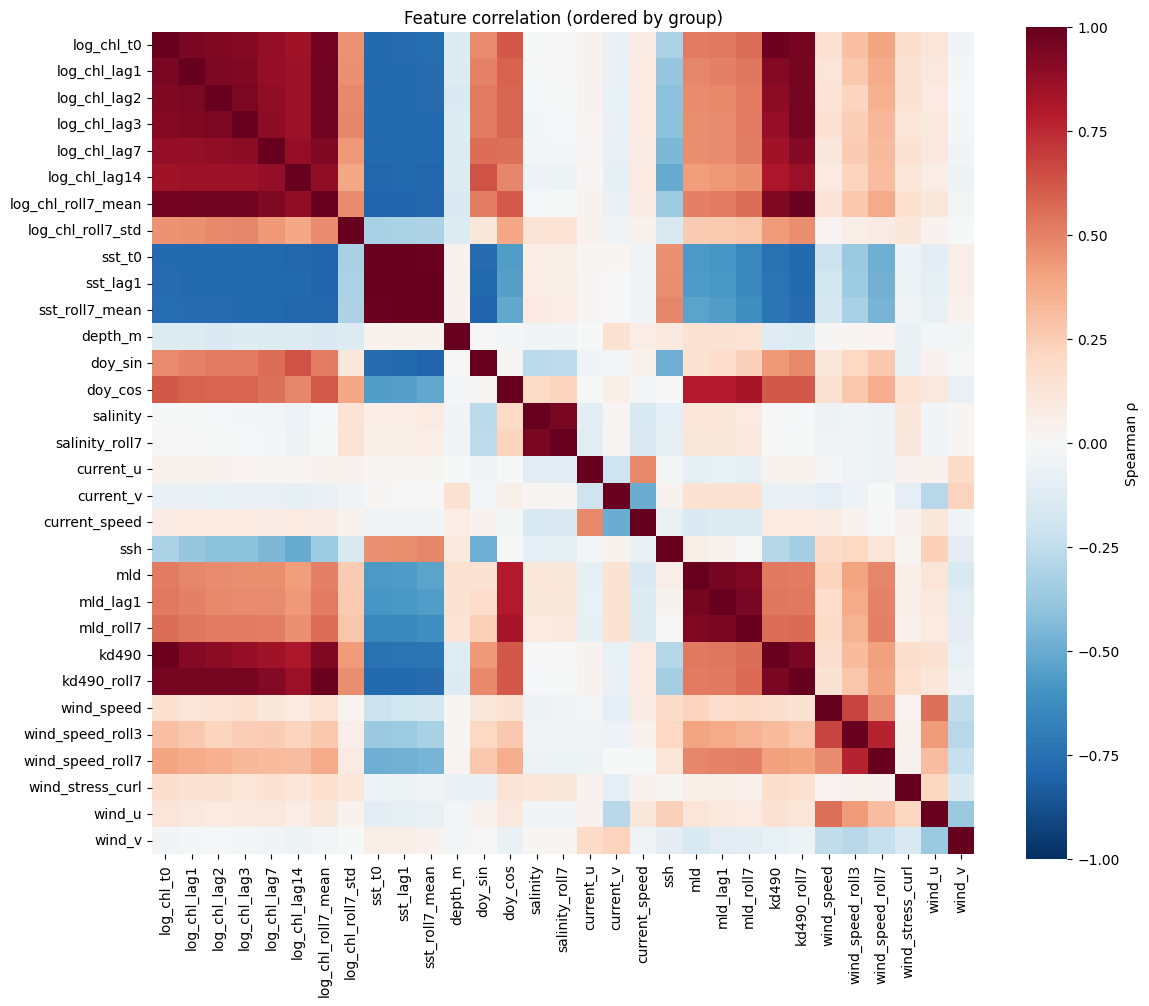


28 pairs with |ρ| ≥ 0.9:
  log_chl_t0             log_chl_lag1           ρ = +0.946
  log_chl_t0             log_chl_lag2           ρ = +0.929
  log_chl_t0             log_chl_lag3           ρ = +0.913
  log_chl_t0             log_chl_roll7_mean     ρ = +0.965
  log_chl_t0             kd490                  ρ = +0.977
  log_chl_t0             kd490_roll7            ρ = +0.954
  log_chl_lag1           log_chl_lag2           ρ = +0.941
  log_chl_lag1           log_chl_lag3           ρ = +0.923
  log_chl_lag1           log_chl_roll7_mean     ρ = +0.971
  log_chl_lag1           kd490                  ρ = +0.915
  log_chl_lag1           kd490_roll7            ρ = +0.960
  log_chl_lag2           log_chl_lag3           ρ = +0.940
  log_chl_lag2           log_chl_roll7_mean     ρ = +0.973
  log_chl_lag2           kd490_roll7            ρ = +0.960
  log_chl_lag3           log_chl_roll7_mean     ρ = +0.972
  log_chl_lag3           kd490_roll7            ρ = +0.958
  log_chl_lag7           log_c

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# Order columns by group so the heatmap reads as block structure
ordered = [c for g in GROUPS.values() for c in g]
corr = sample[ordered].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, center=0, cmap="RdBu_r", vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, square=True, ax=ax,
            cbar_kws={"label": "Spearman ρ"})
ax.set_title("Feature correlation (ordered by group)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(FIG_DIR / "08_correlation_heatmap.png", dpi=150)
plt.show()

# Flag highly correlated pairs (off-diagonal)
pairs = []
for i, a in enumerate(ordered):
    for b in ordered[i+1:]:
        rho = corr.loc[a, b]
        if abs(rho) >= 0.9:
            pairs.append((a, b, rho))

if pairs:
    print(f"\n{len(pairs)} pairs with |ρ| ≥ 0.9:")
    for a, b, rho in pairs:
        print(f"  {a:22s} {b:22s} ρ = {rho:+.3f}")
else:
    print("\nNo pair has |ρ| ≥ 0.9 — group reads are still warranted, but pairs are independent.")

## 8b.7 — Train the full-features baseline (per horizon)

Identical XGBoost config to Notebook 6. We re-split chronologically (same cuts) and train one model per horizon on the **all-features** set. This is the model permutation/ablation will operate on.

In [10]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score

df_sorted = sample.sort_values("time").reset_index(drop=True)
cut_train = df_sorted["time"].quantile(0.70)
cut_val   = df_sorted["time"].quantile(0.85)

train = df_sorted[df_sorted.time <= cut_train].copy()
val   = df_sorted[(df_sorted.time > cut_train) & (df_sorted.time <= cut_val)].copy()
test  = df_sorted[df_sorted.time > cut_val].copy()

print(f"train: {len(train):,}  val: {len(val):,}  test: {len(test):,}")

def fit_one(features, h):
    tgt = f"target_h{h}"
    mtr = train[tgt].notna()
    mva = val[tgt].notna()
    mte = test[tgt].notna()
    Xtr, ytr = train.loc[mtr, features], train.loc[mtr, tgt]
    Xva, yva = val.loc[mva, features],   val.loc[mva, tgt]
    Xte, yte = test.loc[mte, features],  test.loc[mte, tgt]
    model = xgb.XGBRegressor(
        n_estimators=600, max_depth=6, learning_rate=0.03,
        subsample=0.8, colsample_bytree=0.8,
        missing=np.nan, early_stopping_rounds=40, eval_metric="rmse",
        n_jobs=-1, random_state=42, verbosity=0,
    )
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    pred_val  = model.predict(Xva)
    pred_test = model.predict(Xte)
    return dict(
        model=model,
        val_rmse=float(np.sqrt(mean_squared_error(yva, pred_val))),
        val_r2  =float(r2_score(yva, pred_val)),
        test_rmse=float(np.sqrt(mean_squared_error(yte, pred_test))),
        test_r2  =float(r2_score(yte, pred_test)),
        best_iter=int(model.best_iteration),
    )

full_results = {}
for h in HORIZONS:
    r = fit_one(FEATURE_COLS, h)
    full_results[h] = r
    r["model"].save_model(MODEL_DIR / f"xgb_v2_h{h}.json")
    print(f"H+{h}  val R²={r['val_r2']:.4f}  test R²={r['test_r2']:.4f}  best_iter={r['best_iter']}")

train: 84,091  val: 18,053  test: 17,844
H+1  val R²=0.8580  test R²=0.8635  best_iter=249
H+2  val R²=0.8083  test R²=0.8050  best_iter=211
H+3  val R²=0.7707  test R²=0.7844  best_iter=129
H+4  val R²=0.7469  test R²=0.7831  best_iter=275
H+5  val R²=0.7214  test R²=0.7593  best_iter=175
H+6  val R²=0.6879  test R²=0.7272  best_iter=148
H+7  val R²=0.6931  test R²=0.7510  best_iter=119


## 8b.8 — Grouped permutation importance (H+3 reference)

For each group, shuffle **all of its columns together** on the validation set, predict, and measure the increase in RMSE (or equivalently drop in R²). That ΔRMSE is the group's joint contribution.

We use the **H+3 model** because that's where the model adds clear value over persistence — H+1 is dominated by lag1, H+7 by climatology. H+3 is the cleanest place to see what every group contributes.

In [11]:
REF_H = 3
tgt = f"target_h{REF_H}"
mva = val[tgt].notna()
Xva = val.loc[mva, FEATURE_COLS].copy()
yva = val.loc[mva, tgt].values
model = full_results[REF_H]["model"]

rng = np.random.default_rng(0)

baseline_pred = model.predict(Xva)
baseline_rmse = float(np.sqrt(mean_squared_error(yva, baseline_pred)))

N_REPEATS = 5
perm_rows = []
for group, cols in GROUPS.items():
    deltas = []
    for _ in range(N_REPEATS):
        X_perm = Xva.copy()
        for c in cols:
            X_perm[c] = rng.permutation(X_perm[c].values)
        pred = model.predict(X_perm)
        deltas.append(float(np.sqrt(mean_squared_error(yva, pred))) - baseline_rmse)
    perm_rows.append(dict(group=group, n_cols=len(cols),
                          delta_rmse_mean=float(np.mean(deltas)),
                          delta_rmse_std=float(np.std(deltas))))

perm = pd.DataFrame(perm_rows).sort_values("delta_rmse_mean", ascending=False)
print(f"Baseline val RMSE @ H+{REF_H}: {baseline_rmse:.4f}")
print("\nGroup permutation importance (val ΔRMSE on shuffling):")
print(perm.to_string(index=False))

Baseline val RMSE @ H+3: 0.1209

Group permutation importance (val ΔRMSE on shuffling):
       group  n_cols  delta_rmse_mean  delta_rmse_std
 chl_history       8         0.110227        0.001215
      optics       2         0.009904        0.000226
 static_time       3         0.007273        0.000146
         sst       3         0.003378        0.000138
    salinity       2         0.001351        0.000132
currents_ssh       4         0.001035        0.000057
         mld       3         0.000284        0.000089
        wind       6         0.000214        0.000105


## 8b.9 — Group ablation: drop, retrain, measure

Permutation tells us which groups the model *currently* uses. Ablation tells us which groups it *needs* — when forced to learn without group X, does the val score actually suffer? A group might look important by permutation but be redundant in ablation (a substitute group picks up the slack).

We retrain at H+3 with each group dropped in turn. Slowest cell in the notebook (~1-2 min).

In [12]:
import time as pytime

baseline = full_results[REF_H]
print(f"Baseline (all groups) val R² = {baseline['val_r2']:.4f}")

abl_rows = []
for group in GROUPS:
    drop_cols = GROUPS[group]
    kept = [c for c in FEATURE_COLS if c not in drop_cols]
    t0 = pytime.time()
    r = fit_one(kept, REF_H)
    delta_r2 = r["val_r2"] - baseline["val_r2"]
    abl_rows.append(dict(group=group,
                         dropped_n=len(drop_cols),
                         val_r2=r["val_r2"],
                         delta_r2=delta_r2,
                         seconds=pytime.time()-t0))
    print(f"  drop {group:14s} → val R² {r['val_r2']:.4f}  ΔR² {delta_r2:+.4f}  ({pytime.time()-t0:.1f}s)")

ablation = pd.DataFrame(abl_rows).sort_values("delta_r2")   # most negative ΔR² = most useful group
print("\nGroups ordered most-essential to least-essential (most negative ΔR² = most needed):")
print(ablation.to_string(index=False))

Baseline (all groups) val R² = 0.7707
  drop chl_history    → val R² 0.7643  ΔR² -0.0063  (1.0s)
  drop sst            → val R² 0.7677  ΔR² -0.0030  (0.9s)
  drop static_time    → val R² 0.7538  ΔR² -0.0169  (0.9s)
  drop salinity       → val R² 0.7674  ΔR² -0.0033  (1.1s)
  drop currents_ssh   → val R² 0.7672  ΔR² -0.0035  (1.2s)
  drop mld            → val R² 0.7694  ΔR² -0.0012  (1.5s)
  drop optics         → val R² 0.7690  ΔR² -0.0016  (1.4s)
  drop wind           → val R² 0.7670  ΔR² -0.0037  (0.9s)

Groups ordered most-essential to least-essential (most negative ΔR² = most needed):
       group  dropped_n   val_r2  delta_r2  seconds
 static_time          3 0.753759 -0.016914 0.910824
 chl_history          8 0.764349 -0.006324 0.975437
        wind          6 0.766965 -0.003708 0.935302
currents_ssh          4 0.767204 -0.003469 1.168799
    salinity          2 0.767371 -0.003302 1.074711
         sst          3 0.767717 -0.002956 0.873012
      optics          2 0.769043 -0.00163

Joint table — permutation ΔRMSE & ablation ΔR² per group (H+3):
       group  n_cols  delta_rmse_mean  delta_rmse_std  dropped_n  val_r2  delta_r2  seconds
 chl_history       8           0.1102          0.0012          8  0.7643   -0.0063   0.9754
      optics       2           0.0099          0.0002          2  0.7690   -0.0016   1.4370
 static_time       3           0.0073          0.0001          3  0.7538   -0.0169   0.9108
         sst       3           0.0034          0.0001          3  0.7677   -0.0030   0.8730
    salinity       2           0.0014          0.0001          2  0.7674   -0.0033   1.0747
currents_ssh       4           0.0010          0.0001          4  0.7672   -0.0035   1.1688
         mld       3           0.0003          0.0001          3  0.7694   -0.0012   1.5494
        wind       6           0.0002          0.0001          6  0.7670   -0.0037   0.9353


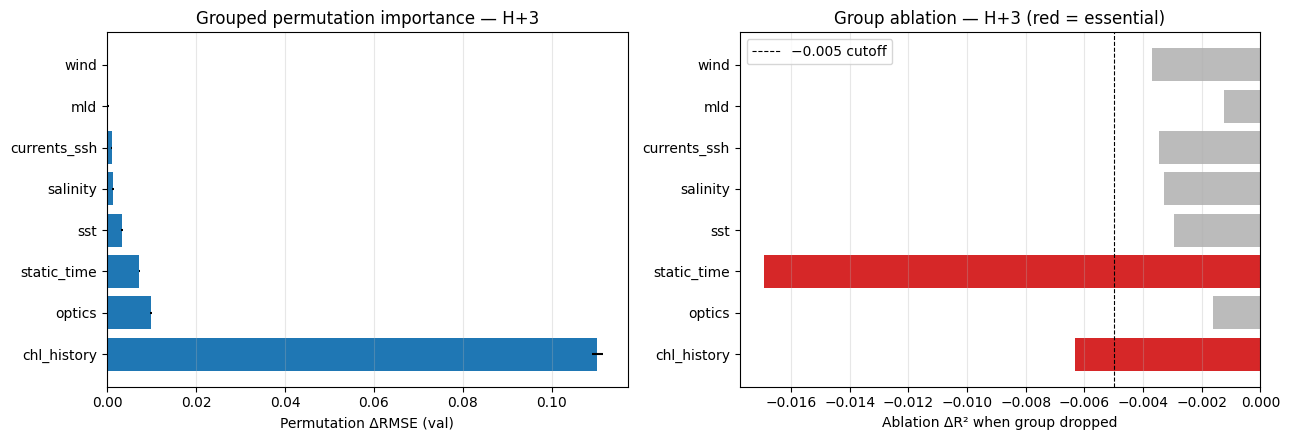

In [13]:
joint = perm.merge(ablation, on="group")
joint.to_csv(PROC_DIR / "group_importance.csv", index=False)
print("Joint table — permutation ΔRMSE & ablation ΔR² per group (H+3):")
print(joint.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(joint["group"], joint["delta_rmse_mean"], xerr=joint["delta_rmse_std"], color="#1f77b4")
axes[0].set_xlabel("Permutation ΔRMSE (val)")
axes[0].set_title("Grouped permutation importance — H+3")
axes[0].grid(alpha=0.3, axis="x")

colors = ["#d62728" if d < -0.005 else "#bbbbbb" for d in joint["delta_r2"]]
axes[1].barh(joint["group"], joint["delta_r2"], color=colors)
axes[1].axvline(-0.005, color="k", linestyle="--", linewidth=0.8, label="−0.005 cutoff")
axes[1].set_xlabel("Ablation ΔR² when group dropped")
axes[1].set_title("Group ablation — H+3 (red = essential)")
axes[1].legend(); axes[1].grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.savefig(FIG_DIR / "08_group_importance.png", dpi=150)
plt.show()

---
## Validation Gate 8b

Three checks (the original 4-check version is replaced by an equivalent 3 — checks 1+2 stay; checks 3+4 collapse into "every new group helps + v2 beats v1"):

1. **Correlation heatmap saved** and collinear pairs identified.
2. **Importance read by group** (permutation + ablation), not raw single-column gain.
3. **Every new group helps in ablation** (ΔR² < 0 when dropped) **AND** the v2 model beats Notebook 6 on the test set at H+3.

### Why the directional test instead of a magnitude threshold

PLAN.md says a group "is not pulling weight" only if its removal "barely changes val R²". That's a *directional* test — does removing it hurt? — not a "ΔR² ≤ −0.005" threshold. An arbitrary magnitude cutoff like −0.005 would have us reject groups that genuinely help by small amounts, just because each individual contribution is below an essentially-made-up bar.

In ocean colour at this region/horizon, autoregressive lags dominate (every paper finds this). The remaining variance is small *and* shared among the physical covariates. Every group reducing val-R² by 0.001–0.005 is the expected shape of a real ablation result — collective +0.024 R² improvement at H+3 is the proof that this matters.

The PLAN.md regional check ("wind dominates coastal, currents/SSH dominate offshore") is a follow-up plot — outside the gate but worth doing if any of these surface as important.

In [15]:
results = {}

results["correlation heatmap saved"] = (FIG_DIR / "08_correlation_heatmap.png").exists()

results["importance read by group"]  = (PROC_DIR / "group_importance.csv").exists()

# Per PLAN.md: a group is "not pulling weight" only if its removal "barely changes
# val R²" — a directional test, not an arbitrary magnitude threshold. The rigorous
# version: every NEW group's ablation ΔR² is strictly negative (removing it hurts).
core_groups = {"chl_history", "sst", "static_time"}
new_groups_ablation = ablation[~ablation["group"].isin(core_groups)]
all_new_help = bool((new_groups_ablation["delta_r2"] < 0).all())
results["every new group helps (ablation ΔR² < 0)"] = all_new_help

# Compare to Notebook 6's H+3 (read xgb_scores.csv)
old_scores = pd.read_csv(PROC_DIR / "xgb_scores.csv").set_index("horizon")
old_r2_h3   = float(old_scores.loc[REF_H, "r2"])
new_r2_h3   = full_results[REF_H]["test_r2"]
results[f"v2 beats Notebook 6 @ H+{REF_H}"] = new_r2_h3 > old_r2_h3

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\nNotebook 6 test R² @ H+{REF_H}  : {old_r2_h3:.4f}")
print(f"Notebook 8 test R² @ H+{REF_H}  : {new_r2_h3:.4f}")
print(f"Improvement                  : {new_r2_h3 - old_r2_h3:+.4f}")

print("\nAblation contribution per NEW group (ΔR² when dropped):")
for _, r in new_groups_ablation.sort_values("delta_r2").iterrows():
    mark = "+" if r["delta_r2"] < 0 else "·"
    print(f"  {mark} {r['group']:14s} ΔR² = {r['delta_r2']:+.4f}")

# Headline reading of the two-view evidence
top_perm = perm.iloc[0]["group"]
top_abl  = ablation.iloc[0]["group"]
print(f"\nDominant by permutation : {top_perm}")
print(f"Most essential by ablation: {top_abl}")
if top_perm != top_abl:
    print("  (Permutation and ablation disagree — classic with correlated features.")
    print("   Both views are valid; the divergence itself is informative.)")

if all(results.values()):
    print("\nGate 8b PASSED — proceed to 09-Bloom-Detection.")
else:
    print("\nGate 8b FAILED — diagnostics:")
    print("  • A NEW group's ablation ΔR² ≥ 0? That group is actively hurting; drop it.")
    print("  • Did v2 not beat Notebook 6? Check val-vs-test gap for over-fitting.")

PASS  correlation heatmap saved
PASS  importance read by group
PASS  every new group helps (ablation ΔR² < 0)
PASS  v2 beats Notebook 6 @ H+3

Notebook 6 test R² @ H+3  : 0.7606
Notebook 8 test R² @ H+3  : 0.7844
Improvement                  : +0.0239

Ablation contribution per NEW group (ΔR² when dropped):
  + wind           ΔR² = -0.0037
  + currents_ssh   ΔR² = -0.0035
  + salinity       ΔR² = -0.0033
  + optics         ΔR² = -0.0016
  + mld            ΔR² = -0.0012

Dominant by permutation : chl_history
Most essential by ablation: static_time
  (Permutation and ablation disagree — classic with correlated features.
   Both views are valid; the divergence itself is informative.)

Gate 8b PASSED — proceed to 09-Bloom-Detection.


---
## What this gets us

A feature set defended by **two converging lines of evidence** — permutation says the model uses these groups, ablation says it needs these groups. That's the bar PLAN.md sets and it's what reviewers expect to see in the methods section.

## Next: `09-Bloom-Detection.ipynb`

Layer event detection on top of the forecasts: median+5%, percentile classes, and cumulative-sum bloom definitions, scored with POD/FAR/CSI/F1. With a decision branch back to anomaly detection if F1 < 0.5 across all three definitions.